# Part 2 lab: a GLM for a binary outcome — 30-day readmission

**Maths for Data Science III · MSHA · Generalized linear models, Part 2 · SOLUTIONS**

In Part 1 we fitted follow-up blood pressure with a GLM that had a **Normal distribution** and an **identity link**, which is ordinary linear regression. Now the outcome is yes/no: was the patient readmitted within 30 days of discharge? We keep the **linear predictor** exactly as it was and change the other two components: a **Binomial distribution** and a **logit link**. That model is logistic regression.

In this notebook you will:

1. See why linear regression fails for a 0/1 outcome.
2. Move between probability, odds and log-odds.
3. Fit logistic regression as a GLM and read its output.
4. Turn coefficients into odds ratios and predicted risks for patients.
5. Check the model with deviance, likelihood-ratio tests and residuals.
6. Judge its predictions: discrimination and calibration.
7. Avoid the classic misreadings: odds ratios read as risk ratios, too few events, separation.
8. See what changes when patients cluster within hospitals.

**Data:** read directly from the course GitHub repository (see *The dataset* below). Full variable definitions are in `hf_cohort_data_dictionary.md`.

**Instructor version.** Answers to the questions are included. The effects built into the data are listed at the end.

## The dataset: a heart-failure discharge cohort

All three GLM sessions use the same dataset: **2,000 adults discharged alive after an admission for heart failure** from **25 US hospitals**, one row per patient. Heart failure is one of the conditions in the CMS Hospital Readmissions Reduction Program, and this is the kind of cohort a US hospital system assembles to follow patients after discharge: who comes back, how often, and how they are doing at the first follow-up visit.

The data are **simulated for teaching**. No row describes a real patient or hospital. Because the data were generated with known effects, we can check how close each model gets to the truth.

**Source:** [`hf_cohort.csv`](https://raw.githubusercontent.com/thousandoaks/Maths4DS-III/refs/heads/main/datasets/hf_cohort.csv) in the course GitHub repository (`thousandoaks/Maths4DS-III`, `datasets/` folder). The notebook reads it straight from that address, so there is no file to download. The file is complete: no missing values.

### What was recorded

| Variable | Description | Units / values |
|---|---|---|
| `patient_id` | Patient identifier | text, e.g. `HF026-00001` |
| `hospital_id` | Discharging hospital | `H01` to `H25` |
| `age` | Age at admission | years (45 to 98) |
| `female` | Sex recorded as female | 1 = female, 0 = male |
| `egfr` | Estimated glomerular filtration rate (kidney function) at admission | mL/min/1.73 m² (8 to 125) |
| `diabetes` | Diabetes on the problem list | 1 = yes, 0 = no |
| `prior_admits_12m` | Hospital admissions for any cause in the 12 months before this one | count (0 to 5) |
| `los_days` | Length of stay of this admission | days, one decimal |
| `sbp_followup` | Systolic blood pressure at the 14-day post-discharge visit | mmHg |
| `readmit_30d` | Unplanned readmission to any hospital within 30 days | 1 = yes, 0 = no |
| `ed_visits_6m` | Emergency department visits during follow-up | count |
| `followup_days` | Days of follow-up for ED visits | 30 to 182 days |

### One cohort, four kinds of outcome

The same patients and predictors appear with four outcomes, each a different kind of number, so each needs a different GLM:

| Outcome | Kind of number | GLM | Where |
|---|---|---|---|
| `sbp_followup` | continuous, roughly symmetric | Normal, identity link | Part 1 |
| `los_days` | positive, right-skewed | Gamma, log link | Part 1 lecture |
| `readmit_30d` | binary (yes / no) | Binomial, logit link | **this notebook** |
| `ed_visits_6m` | count, over `followup_days` | Poisson or negative binomial, log link | Part 3 |

### In this notebook

- **Outcome:** `readmit_30d`, unplanned readmission within 30 days of discharge (1 = yes, 0 = no).
- **Predictors:** `age`, `egfr`, `diabetes` and `prior_admits_12m`, the same four used throughout the series.
- **Clustering:** `hospital_id` in the last section, to see what happens when patients from the same hospital are not independent.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

pd.set_option("display.width", 120)
fam = sm.families

In [2]:
# The cohort lives in the course GitHub repository
DATA_URL = "https://raw.githubusercontent.com/thousandoaks/Maths4DS-III/refs/heads/main/datasets/hf_cohort.csv"

df = pd.read_csv(DATA_URL)
print(df.shape)
df.head()

(2000, 12)


,patient_id,hospital_id,age,female,egfr,diabetes,prior_admits_12m,los_days,sbp_followup,readmit_30d,ed_visits_6m,followup_days
0,HF026-00001,H02,75,0,52,0,2,7.4,147,0,1,182
1,HF026-00002,H01,84,1,48,0,0,1.6,130,0,0,182
2,HF026-00003,H24,81,0,72,0,1,1.1,143,0,0,182
3,HF026-00004,H24,62,0,50,1,1,1.9,140,0,1,122
4,HF026-00005,H12,69,0,39,0,1,0.6,145,0,1,182


As in Part 1, we centre and rescale age and eGFR. Each coefficient is then **per 10 units**, and the intercept describes a **reference patient**: 75 years old, eGFR 60, no diabetes, no admissions in the prior year.

In [3]:
df["age10"] = (df["age"] - 75) / 10
df["egfr10"] = (df["egfr"] - 60) / 10

RHS = "~ age10 + egfr10 + diabetes + prior_admits_12m"

# The two patients from the slides
patients = pd.DataFrame({
    "patient": ["A", "B"],
    "age": [68, 84],
    "egfr": [75, 35],
    "diabetes": [0, 1],
    "prior_admits_12m": [0, 2],
})
patients["age10"] = (patients["age"] - 75) / 10
patients["egfr10"] = (patients["egfr"] - 60) / 10
patients

,patient,age,egfr,diabetes,prior_admits_12m,age10,egfr10
0,A,68,75,0,0,-0.7,1.5
1,B,84,35,1,2,0.9,-2.5


## 1. Look at the outcome first

The first question in choosing a GLM is **what kind of number is the outcome?**

In [4]:
counts = df["readmit_30d"].value_counts().sort_index()
print(counts)
print(f"Readmitted within 30 days: {counts[1]} of {len(df)} = {df['readmit_30d'].mean():.1%}")

readmit_30d
0    1510
1     490
Name: count, dtype: int64
Readmitted within 30 days: 490 of 2000 = 24.5%


For a 0/1 outcome, the mean in any group of patients **is** the proportion readmitted. Look at how that proportion changes with each predictor.

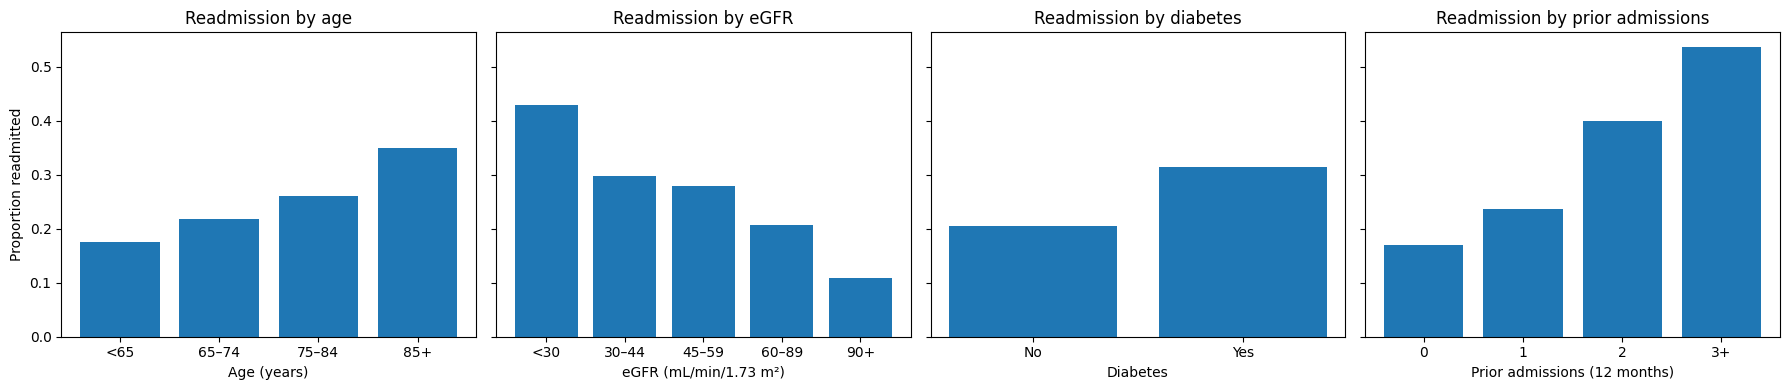

In [5]:
age_band = pd.cut(df["age"], [0, 65, 75, 85, 120], right=False, labels=["<65", "65–74", "75–84", "85+"])
egfr_band = pd.cut(df["egfr"], [0, 30, 45, 60, 90, 200], right=False, labels=["<30", "30–44", "45–59", "60–89", "90+"])
prior_band = df["prior_admits_12m"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})

groups = [
    ("age", "Age (years)", age_band),
    ("eGFR", "eGFR (mL/min/1.73 m²)", egfr_band),
    ("diabetes", "Diabetes", df["diabetes"].map({0: "No", 1: "Yes"})),
    ("prior admissions", "Prior admissions (12 months)", prior_band),
]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, label, g) in zip(axes, groups):
    rate = df.groupby(g, observed=True)["readmit_30d"].mean()
    ax.bar(rate.index.astype(str), rate.values)
    ax.set(title=f"Readmission by {name}", xlabel=label)
axes[0].set_ylabel("Proportion readmitted")
plt.tight_layout()

**Question 1.** What kind of number is `readmit_30d`, and what does that imply for the distribution part of the GLM? What do the bar charts suggest about each predictor?

*Answer.* It is binary: each patient is either readmitted (1) or not (0). Its mean is a probability, which must stay between 0 and 1, and its variance is p(1 − p), so it depends on the risk itself. The natural distribution is the **Binomial** (strictly, the Bernoulli: one trial per patient). Unadjusted, readmission rises with age (from about 18% under 65 to 35% at 85 and over), falls steeply with better kidney function (43% with eGFR under 30, 11% at 90 and over), is higher with diabetes (31.5% against 20.5%) and climbs with prior admissions (17% with none, over 50% with three or more).

## 2. Why not linear regression?

The **linear probability model** fits ordinary least squares to the 0/1 outcome.

In [6]:
lpm = smf.ols("readmit_30d" + RHS, data=df).fit()
pred = lpm.fittedvalues
print(f"Predicted 'probabilities' range from {pred.min():.3f} to {pred.max():.3f}")
print(f"Patients with a predicted probability below 0: {(pred < 0).sum()}")

Predicted 'probabilities' range from -0.099 to 0.844
Patients with a predicted probability below 0: 12


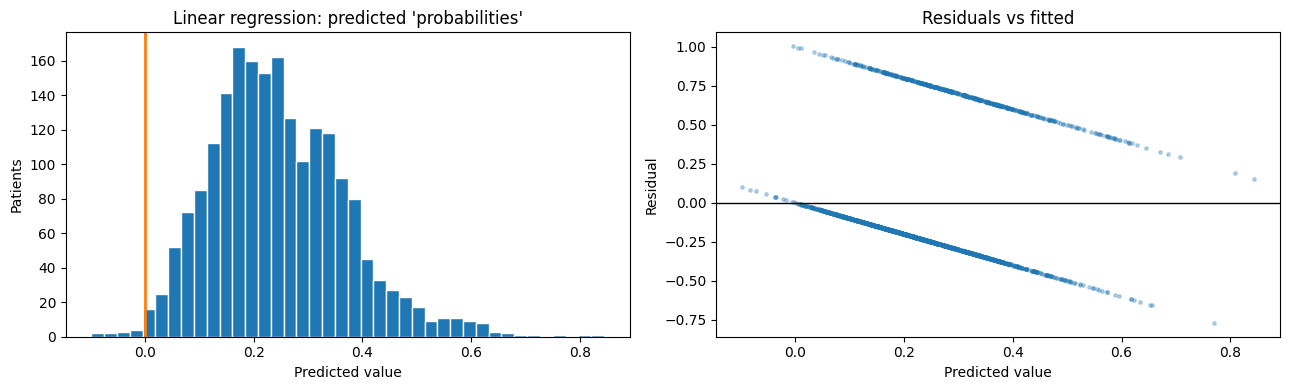

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(pred, bins=40, edgecolor="white")
axes[0].axvline(0, color="tab:orange", lw=2)
axes[0].set(title="Linear regression: predicted 'probabilities'", xlabel="Predicted value", ylabel="Patients")
axes[1].scatter(pred, lpm.resid, s=6, alpha=0.3)
axes[1].axhline(0, color="black", lw=1)
axes[1].set(title="Residuals vs fitted", xlabel="Predicted value", ylabel="Residual")
plt.tight_layout()

**Question 2.** List the problems these two plots reveal.

*Answer.*
1. **Impossible predictions:** 12 patients get a negative "probability" of readmission; nothing would stop predictions above 1 either.
2. **Wrong variance:** the residuals form two bands (one for 0s and one for 1s) whose spread depends on the fitted value, because the variance of a 0/1 outcome is p(1 − p). OLS assumes constant variance, so its standard errors are wrong.
3. **Wrong shape:** OLS adds the same number of percentage points for a risk factor in every patient, which is impossible for a patient already near 100% (or near 0%).

## 3. Probability, odds and log-odds

Logistic regression works on the **log-odds** scale, so it is worth getting fluent with the three scales.

- **Odds** = p / (1 − p): patients with the event per patient without it.
- **Log-odds** = log(odds), also called the **logit** of p.

In [8]:
p = df["readmit_30d"].mean()
odds = p / (1 - p)
print(f"Probability {p:.3f}   odds {odds:.3f}   log-odds {np.log(odds):.3f}")

Probability 0.245   odds 0.325   log-odds -1.125


In [9]:
probs = np.array([0.10, p, 0.50, 0.75, 0.90])
pd.DataFrame({
    "probability": probs,
    "odds": probs / (1 - probs),
    "log-odds": np.log(probs / (1 - probs)),
}).round(3)

,probability,odds,log-odds
0,0.100,0.111,-2.197
1,0.245,0.325,-1.125
2,0.500,1.000,0.000
3,0.750,3.000,1.099
4,0.900,9.000,2.197


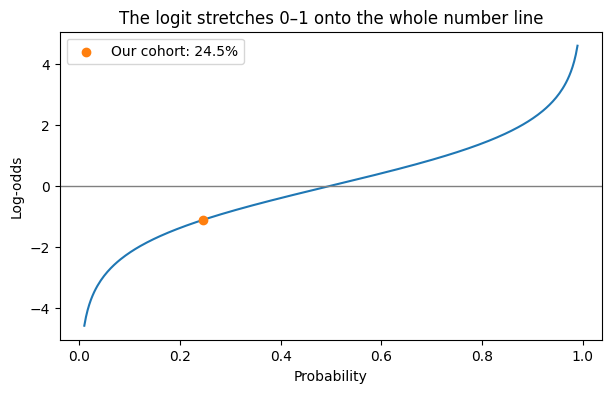

In [10]:
pp = np.linspace(0.01, 0.99, 300)
plt.figure(figsize=(7, 4))
plt.plot(pp, np.log(pp / (1 - pp)))
plt.axhline(0, color="grey", lw=1)
plt.scatter([p], [np.log(odds)], color="tab:orange", zorder=3, label=f"Our cohort: {p:.1%}")
plt.xlabel("Probability")
plt.ylabel("Log-odds")
plt.title("The logit stretches 0–1 onto the whole number line")
plt.legend()
plt.show()

Probability is squeezed between 0 and 1, odds run from 0 to infinity, and log-odds run over the whole number line, symmetric around 50% (10% and 90% are −2.20 and +2.20). That is the scale on which a linear predictor can add up effects without ever producing an impossible probability. Notice too that for small risks odds and probability are close (10% against 0.11), but for common outcomes they diverge. That is the root of the odds-ratio trap in Section 10.

## 4. Logistic regression as a GLM

Use `smf.glm` with the **Binomial** family. Its default link is the **logit**.

In [11]:
logit = smf.glm("readmit_30d" + RHS, data=df, family=fam.Binomial()).fit()
print(logit.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:            readmit_30d   No. Observations:                 2000
Model:                            GLM   Df Residuals:                     1995
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1031.3
Date:                Thu, 29 Oct 2026   Deviance:                       2062.5
Time:                        12:57:55   Pearson chi2:                 1.98e+03
No. Iterations:                     4   Pseudo R-squ. (CS):            0.07900
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -1.7475      0.088  

### The three components, inside the fitted model

In [12]:
print("1. Distribution (family):", type(logit.family).__name__)
print("2. Linear predictor:     ", " + ".join(logit.params.index))
print("3. Link function:        ", type(logit.family.link).__name__)

1. Distribution (family): Binomial
2. Linear predictor:      Intercept + age10 + egfr10 + diabetes + prior_admits_12m
3. Link function:         Logit


### The linear predictor is no longer the prediction

In Part 1, with the identity link, the linear predictor η and the predicted mean were the same thing. With the logit link they are different: η is on the log-odds scale, and the predicted risk is the **inverse logit** of η, p = exp(η) / (1 + exp(η)).

In [13]:
eta = logit.predict(which="linear")   # linear predictor (log-odds)
risk = logit.predict()                # predicted probability
check = pd.DataFrame({"eta (log-odds)": eta[:5], "predicted risk": risk[:5],
                      "exp(eta)/(1+exp(eta))": np.exp(eta[:5]) / (1 + np.exp(eta[:5]))})
print("Inverse logit reproduces the predictions:", np.allclose(risk, np.exp(eta) / (1 + np.exp(eta))))
check.round(4)

Inverse logit reproduces the predictions: True


,eta (log-odds),predicted risk,exp(eta)/(1+exp(eta))
0,-0.6899,0.3341,0.3341
1,-1.4039,0.1972,0.1972
2,-1.3714,0.2024,0.2024
3,-0.8825,0.2927,0.2927
4,-1.0501,0.2592,0.2592


## 5. Reading the output

Every number in the coefficient table is on the **log-odds** scale.

In [14]:
ci = logit.conf_int()
coef_table = pd.DataFrame({
    "β (log-odds)": logit.params,
    "SE": logit.bse,
    "z": logit.tvalues,
    "p-value": logit.pvalues,
    "2.5%": ci[0],
    "97.5%": ci[1],
}).round(3)
coef_table

,β (log-odds),SE,z,p-value,2.5%,97.5%
Intercept,-1.748,0.088,-19.792,0.000,-1.921,-1.574
age10,0.170,0.058,2.933,0.003,0.056,0.283
egfr10,-0.159,0.031,-5.110,0.000,-0.220,-0.098
diabetes,0.461,0.111,4.166,0.000,0.244,0.678
prior_admits_12m,0.465,0.057,8.144,0.000,0.353,0.577


How to read it:

- **Sign:** β > 0 raises the risk, β < 0 lowers it. Age, diabetes and prior admissions raise it; better kidney function lowers it.
- **z = β ÷ SE** is the Wald statistic, and its p-value tests "no effect".
- **95% CI** = β ± 1.96 × SE, still on the log-odds scale.
- **β is not a change in risk.** A coefficient of 0.46 does not mean "46% more risk". The next section shows how to translate it.

## 6. Odds ratios

Exponentiate a coefficient and you get an **odds ratio**: the factor by which the odds are multiplied, holding the other predictors fixed. Exponentiate the confidence limits too (never the standard error).

In [15]:
def ratio_table(model, label="ratio"):
    """exp(coefficients) with 95% CI and p-values."""
    ci = np.exp(model.conf_int())
    return pd.DataFrame({label: np.exp(model.params), "2.5%": ci[0], "97.5%": ci[1],
                         "p-value": model.pvalues}).round(3)

or_table = ratio_table(logit, "odds ratio")
or_table

,odds ratio,2.5%,97.5%,p-value
Intercept,0.174,0.147,0.207,0.000
age10,1.185,1.058,1.327,0.003
egfr10,0.853,0.802,0.907,0.000
diabetes,1.586,1.277,1.971,0.000
prior_admits_12m,1.592,1.424,1.781,0.000


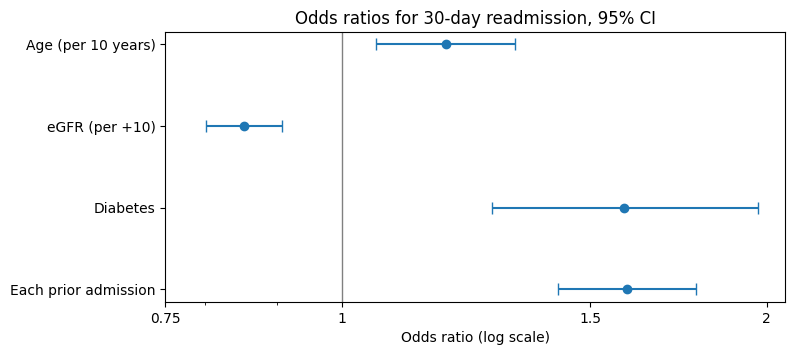

In [16]:
labels = {"age10": "Age (per 10 years)", "egfr10": "eGFR (per +10)",
          "diabetes": "Diabetes", "prior_admits_12m": "Each prior admission"}
t = or_table.loc[list(labels)]
y = np.arange(len(t))[::-1]
plt.figure(figsize=(8, 3.5))
plt.errorbar(t["odds ratio"], y, xerr=[t["odds ratio"] - t["2.5%"], t["97.5%"] - t["odds ratio"]],
             fmt="o", capsize=4)
plt.axvline(1, color="grey", lw=1)
plt.xscale("log")
plt.xticks([0.75, 1, 1.5, 2], ["0.75", "1", "1.5", "2"])
plt.yticks(y, labels.values())
plt.xlabel("Odds ratio (log scale)")
plt.title("Odds ratios for 30-day readmission, 95% CI")
plt.show()

Two worked interpretations:

- **Diabetes:** exp(0.461) = 1.59. Diabetes multiplies the odds of readmission by 1.59 (95% CI 1.28 to 1.97), compared with patients without diabetes of the same age, kidney function and admission history.
- **Intercept:** exp(−1.75) = 0.17 is the reference patient's **odds**, which is a **risk** of 0.17 / 1.17 = 15%.

Two consequences of working on a multiplicative scale:

In [17]:
b = logit.params
print(f"Reference patient: odds {np.exp(b['Intercept']):.3f}, risk {np.exp(b['Intercept']) / (1 + np.exp(b['Intercept'])):.1%}")
print(f"Age: OR per 10 years {np.exp(b['age10']):.3f}  =  OR per single year {np.exp(b['age10'] / 10):.4f}")
for k in [1, 2, 3]:
    print(f"{k} prior admission(s): odds multiplied by {np.exp(k * b['prior_admits_12m']):.2f}")

Reference patient: odds 0.174, risk 14.8%
Age: OR per 10 years 1.185  =  OR per single year 1.0171
1 prior admission(s): odds multiplied by 1.59
2 prior admission(s): odds multiplied by 2.54
3 prior admission(s): odds multiplied by 4.04


**Question 3.** Write one sentence each for the age and eGFR odds ratios, in a form you could put in a clinical paper.

*Answer.*

- **Age:** each additional 10 years of age multiplies the odds of 30-day readmission by 1.18 (95% CI 1.06 to 1.33), adjusting for kidney function, diabetes and prior admissions.
- **eGFR:** each 10 mL/min/1.73 m² higher eGFR multiplies the odds by 0.85 (0.80 to 0.91), that is, 15% lower odds, adjusting for the other predictors.

The unit is a choice: per single year the age odds ratio is 1.017, the same effect expressed differently. Always say which unit an odds ratio refers to.

## 7. Predicted risks for individual patients

Odds ratios describe comparisons; **predicted risks** describe patients. `get_prediction` returns each patient's risk with a 95% confidence interval, already converted back to the probability scale.

In [18]:
pr = logit.get_prediction(patients).summary_frame(alpha=0.05)
patients[["patient", "age", "egfr", "diabetes", "prior_admits_12m"]].join(
    pr[["mean", "mean_ci_lower", "mean_ci_upper"]].rename(
        columns={"mean": "risk", "mean_ci_lower": "lower", "mean_ci_upper": "upper"}).round(3))

,patient,age,egfr,diabetes,prior_admits_12m,risk,lower,upper
0,A,68,75,0,0,0.109,0.09,0.130
1,B,84,35,1,2,0.549,0.49,0.606


The same calculation by hand for Patient B (84 years, eGFR 35, diabetes, 2 prior admissions): add up the linear predictor, then apply the inverse logit.

In [19]:
xB = {"Intercept": 1, "age10": 0.9, "egfr10": -2.5, "diabetes": 1, "prior_admits_12m": 2}
eta_B = sum(b[k] * v for k, v in xB.items())
print(f"eta_B = {eta_B:.3f} (log-odds)   ->   risk = exp(eta)/(1+exp(eta)) = {np.exp(eta_B) / (1 + np.exp(eta_B)):.3f}")

eta_B = 0.195 (log-odds)   ->   risk = exp(eta)/(1+exp(eta)) = 0.549


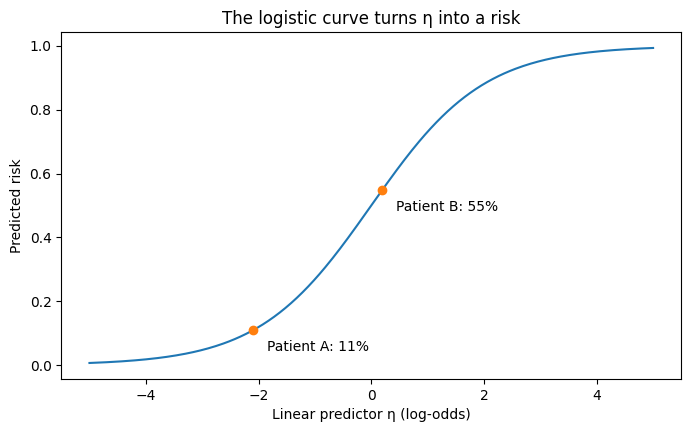

In [20]:
e = np.linspace(-5, 5, 300)
plt.figure(figsize=(8, 4.5))
plt.plot(e, np.exp(e) / (1 + np.exp(e)))
eta_pts = logit.predict(patients, which="linear")
risk_pts = logit.predict(patients)
for name, et, rk in zip(["A", "B"], eta_pts, risk_pts):
    plt.scatter(et, rk, color="tab:orange", zorder=3)
    plt.annotate(f"Patient {name}: {rk:.0%}", (et, rk), xytext=(10, -15), textcoords="offset points")
plt.xlabel("Linear predictor η (log-odds)")
plt.ylabel("Predicted risk")
plt.title("The logistic curve turns η into a risk")
plt.show()

The same coefficient moves the risk by different amounts depending on where a patient sits on the curve. Adding diabetes (+0.46 on the log-odds scale) to a patient at 11% and to a patient at 45%:

In [21]:
for p0 in [0.11, 0.45]:
    eta0 = np.log(p0 / (1 - p0))
    p1 = np.exp(eta0 + b["diabetes"]) / (1 + np.exp(eta0 + b["diabetes"]))
    print(f"Baseline risk {p0:.0%} -> {p1:.1%}: +{100 * (p1 - p0):.1f} percentage points")

Baseline risk 11% -> 16.4%: +5.4 percentage points
Baseline risk 45% -> 56.5%: +11.5 percentage points


## 8. Checking the model

### Deviance and the likelihood-ratio test

Deviance is the GLM version of the residual sum of squares. The drop from the **null deviance** (no predictors) shows how much the predictors explain. To ask whether prior admissions add anything, compare nested models: the difference in deviance is the **likelihood-ratio** statistic.

In [22]:
logit_small = smf.glm("readmit_30d ~ age10 + egfr10 + diabetes", data=df, family=fam.Binomial()).fit()
lr = logit_small.deviance - logit.deviance
print(f"Null deviance {logit.null_deviance:,.1f}  ->  with four predictors {logit.deviance:,.1f}")
print(f"Without prior admissions {logit_small.deviance:,.1f}: LR statistic {lr:.1f} on 1 df, p = {stats.chi2.sf(lr, 1):.1e}")
print(f"AIC {logit_small.aic:.1f} -> {logit.aic:.1f} (lower is better)")

Null deviance 2,227.1  ->  with four predictors 2,062.5
Without prior admissions 2,130.2: LR statistic 67.7 on 1 df, p = 1.9e-16
AIC 2138.2 -> 2072.5 (lower is better)


### Residuals for a binary outcome

Raw residuals from a 0/1 outcome always form two bands, so they are hard to read. Instead, sort patients into 20 groups by predicted risk (or by a predictor), and plot the **average residual** in each group against a band of ±2 standard errors. Points should scatter around zero with no trend, mostly inside the band.

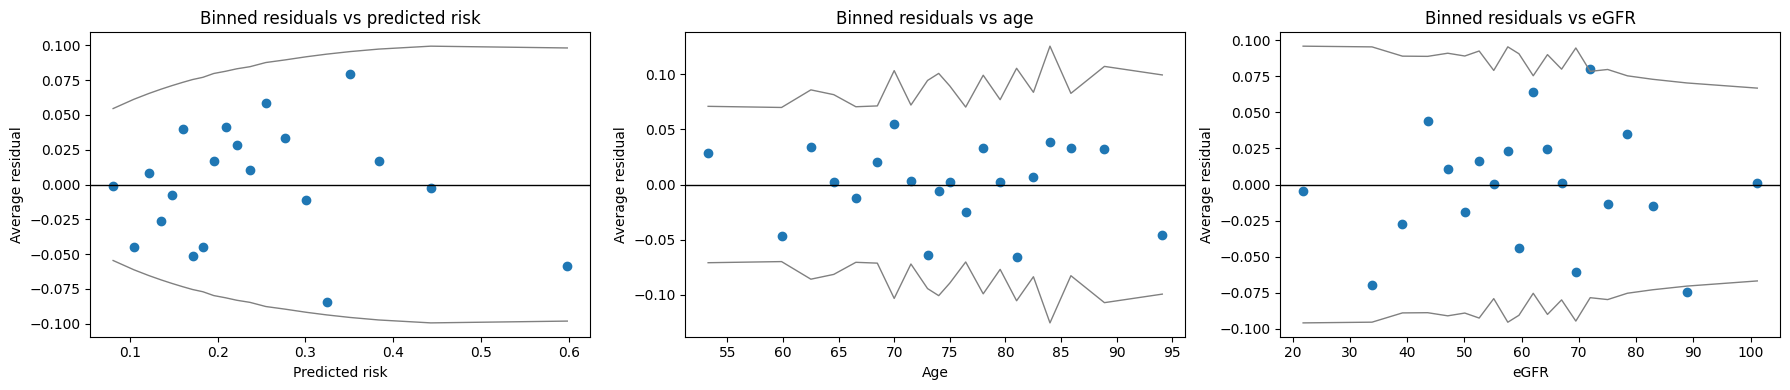

In [23]:
def binned_residuals(x, fitted, observed, n_bins=20):
    d = pd.DataFrame({"x": x, "fit": fitted, "res": observed - fitted})
    d["bin"] = pd.qcut(d["x"], n_bins, duplicates="drop")
    g = d.groupby("bin", observed=True)
    out = pd.DataFrame({"x": g["x"].mean(), "res": g["res"].mean(), "n": g.size(), "fit": g["fit"].mean()})
    out["band"] = 2 * np.sqrt(out["fit"] * (1 - out["fit"]) / out["n"])
    return out

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (x, label, name) in zip(axes, [(logit.fittedvalues, "Predicted risk", "predicted risk"),
                                        (df["age"], "Age", "age"), (df["egfr"], "eGFR", "eGFR")]):
    br = binned_residuals(x, logit.fittedvalues, df["readmit_30d"])
    ax.plot(br["x"], br["band"], color="grey", lw=1)
    ax.plot(br["x"], -br["band"], color="grey", lw=1)
    ax.scatter(br["x"], br["res"])
    ax.axhline(0, color="black", lw=1)
    ax.set(title=f"Binned residuals vs {name}", xlabel=label, ylabel="Average residual")
plt.tight_layout()

**Question 4.** Do the deviance comparison and the binned residuals give any reason to doubt the model?

*Answer.* No. Prior admissions clearly improve the fit (deviance drops by 68 on 1 df, p < 0.001, and AIC falls by 66). The binned residuals scatter around zero with no trend against predicted risk, age or eGFR, and nearly all lie inside the ±2 SE band, so there is no sign that the effects of age or eGFR are curved on the log-odds scale. A systematic curve against a predictor would suggest adding a squared term or a spline for it.

## 9. Judging the predictions: discrimination and calibration

Two different questions about a risk model:

- **Discrimination:** does it rank patients correctly? The **C-statistic** (area under the ROC curve) is the probability that a randomly chosen readmitted patient has a higher predicted risk than a randomly chosen patient who was not readmitted. 0.5 is a coin toss; 1 is perfect.
- **Calibration:** are the numbers right? In groups of patients with similar predicted risk, does the observed readmission rate match the prediction?

C-statistic: 0.687


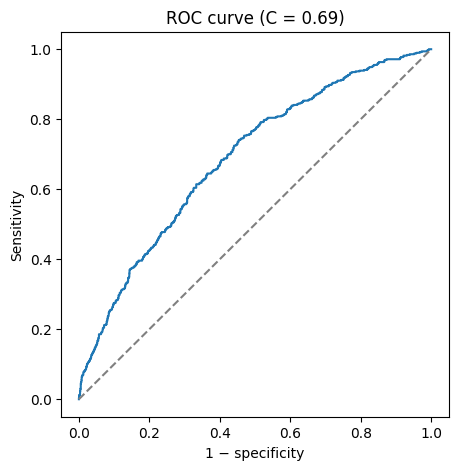

In [24]:
y = df["readmit_30d"].to_numpy()
p_hat = logit.fittedvalues.to_numpy()

# C-statistic via the Mann-Whitney U statistic
u = stats.mannwhitneyu(p_hat[y == 1], p_hat[y == 0]).statistic
c_stat = u / ((y == 1).sum() * (y == 0).sum())
print(f"C-statistic: {c_stat:.3f}")

# ROC curve: sensitivity and 1 - specificity at every threshold
thresholds = np.sort(np.unique(p_hat))[::-1]
sens = [(p_hat[y == 1] >= t).mean() for t in thresholds]
fpr = [(p_hat[y == 0] >= t).mean() for t in thresholds]
plt.figure(figsize=(5, 5))
plt.plot([0] + fpr, [0] + sens)
plt.plot([0, 1], [0, 1], color="grey", ls="--")
plt.xlabel("1 − specificity")
plt.ylabel("Sensitivity")
plt.title(f"ROC curve (C = {c_stat:.2f})")
plt.show()

Hosmer-Lemeshow chi-square 13.4 on 8 df, p = 0.10


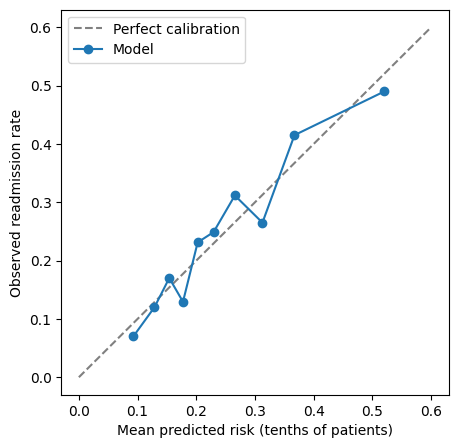

,predicted,observed,n
decile,,,
0,0.093,0.070,200
1,0.129,0.120,200
2,0.154,0.170,200
3,0.177,0.129,201
4,0.202,0.231,199
5,0.229,0.249,201
6,0.266,0.312,199
7,0.313,0.265,200
8,0.367,0.415,200


In [25]:
cal = pd.DataFrame({"p": p_hat, "y": y})
cal["decile"] = pd.qcut(cal["p"], 10, labels=False)
cal = cal.groupby("decile").agg(predicted=("p", "mean"), observed=("y", "mean"), n=("y", "size"))

hl = (((cal["observed"] - cal["predicted"]) * cal["n"]) ** 2
      / (cal["n"] * cal["predicted"] * (1 - cal["predicted"]))).sum()
print(f"Hosmer-Lemeshow chi-square {hl:.1f} on 8 df, p = {stats.chi2.sf(hl, 8):.2f}")

plt.figure(figsize=(5, 5))
plt.plot([0, 0.6], [0, 0.6], color="grey", ls="--", label="Perfect calibration")
plt.plot(cal["predicted"], cal["observed"], "o-", label="Model")
plt.xlabel("Mean predicted risk (tenths of patients)")
plt.ylabel("Observed readmission rate")
plt.legend()
plt.show()
cal.round(3)

**Question 5.** How would you describe this model's performance to a heart-failure programme lead who wants to target a transitional-care intervention?

*Answer.* The model is **well calibrated**: in every tenth of patients the observed readmission rate is close to the predicted one (Hosmer–Lemeshow p = 0.10), so a predicted 30% can be taken at face value. Its **discrimination is modest** (C = 0.69): it separates high-risk from low-risk patients better than chance but far from perfectly, which is typical of readmission models built from a handful of chart variables. It is useful for ranking patients to prioritise an intervention, not for deciding with confidence who will be readmitted. Both measures were computed on the patients used to fit the model, which flatters them; a proper evaluation uses new patients or cross-validation.